##AI-Based Individual Health Risk Prediction Platform

CDC BRFSS 2025 | Google Colab implementation

1. Download official CDC BRFSS 2025 SAS Transport file

In [1]:
import os, zipfile, requests, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve)
from sklearn.inspection import permutation_importance
RANDOM_STATE = 42
print("Libraries ready.")

Libraries ready.


2. Extract and load the XPT file

In [6]:
URL = "https://www.cdc.gov/brfss/annual_data/2025/files/LLCP2025XPT.zip"
zip_path = "/content/LLCP2025XPT.zip"
r = requests.get(URL, timeout=300)
r.raise_for_status()
if not r.content.startswith(b"PK"):
    raise ValueError("Download did not return a ZIP file. Check the CDC download page.")
with open(zip_path, "wb") as f:
    f.write(r.content)
print("Downloaded MB:", round(len(r.content)/(1024**2), 2))

Downloaded MB: 61.65


In [11]:
import zipfile
import os

zip_path = "/content/LLCP2025XPT.zip"

print("ZIP file exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("\nFiles inside ZIP:")
    for name in z.namelist():
        print(name)

ZIP file exists: True

Files inside ZIP:
LLCP2025.XPT 


In [12]:
import os

print("ZIP size (MB):",
      round(os.path.getsize(zip_path) / (1024 * 1024), 2))

with open(zip_path, "rb") as f:
    print("File signature:", f.read(10))

ZIP size (MB): 61.65
File signature: b'PK\x03\x04\x14\x00\x00\x08\x08\x00'


In [21]:
import os

print("Searching for BRFSS dataset...\n")

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.lower() == "llcp2025.xpt":
            print("FOUND:", os.path.join(root, name))

Searching for BRFSS dataset...

FOUND: /content/LLCP2025.XPT


In [22]:
import pandas as pd
import os

file_path = None

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.lower() == "llcp2025.xpt":
            file_path = os.path.join(root, name)
            break
    if file_path:
        break

if file_path:
    print("Loading:", file_path)

    df = pd.read_sas(file_path, format="xport")

    print("\nDataset loaded successfully!")
    print("Dataset dimensions:", df.shape)

    display(df.head())

else:
    print("File not found. Send me the Step 1 output.")

Loading: /content/LLCP2025.XPT

Dataset loaded successfully!
Dataset dimensions: (84017, 283)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [23]:
import os
import pandas as pd

# Find the uploaded XPT file
xpt_files = []

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower() == "llcp2025.xpt":
            xpt_files.append(os.path.join(root, file))

print("Files found:", xpt_files)

# Load the dataset
if xpt_files:
    file_path = xpt_files[0]
    df = pd.read_sas(file_path, format="xport")

    print("\nDataset loaded successfully!")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    display(df.head())
else:
    print("Dataset not found. Check the Colab Files panel.")

Files found: ['/content/LLCP2025.XPT']

Dataset loaded successfully!
Rows: 133038
Columns: 283


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [24]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (133038, 283)

Column Names:
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX4', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX4', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'BPHIGH6', 'BPMEDS1', 'CHOLCHK3', 'TOLDHI3', 'CHOLMED3', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNC1', 'CHCOCNC1', 'CHCCOPD3', 'ADDEPEV3', 'CHCKDNY2', 'HAVARTH4', 'DIABETE4', 'DIABAGE4', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL4', 'NUMPHON4', 'CPDEMO1C', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME3', 'PREGNANT', 'WEIGHT2', 'HEIGHT3', 'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SLEPTIM1', 'SMOKE100', 'SMOKDAY2', 'USENOW3', 'ECIGNOW3', 'ALCDAY4', 'AVEDRNK4', 'DRNK3GE5', 'MAXDRNKS', '

In [25]:
import os
import pandas as pd

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.lower() == "llcp2025.xpt":
            path = os.path.join(root, name)

            print("\nFile:", path)
            print("Size (MB):", round(os.path.getsize(path)/(1024**2), 2))

            temp_df = pd.read_sas(path, format="xport")

            print("Shape:", temp_df.shape)


File: /content/LLCP2025.XPT
Size (MB): 401.0
Shape: (187194, 283)


In [26]:
import os
import pandas as pd

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.lower() == "llcp2025.xpt":

            path = os.path.join(root, name)

            print("\nFile:", path)
            print("Size (MB):", round(os.path.getsize(path)/(1024**2), 2))

            temp = pd.read_sas(path, format="xport")

            print("Rows:", temp.shape[0])
            print("Columns:", temp.shape[1])


File: /content/LLCP2025.XPT
Size (MB): 444.0
Rows: 207269
Columns: 283


In [27]:
import zipfile
import os

zip_path = "/content/LLCP2025XPT.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for info in z.infolist():
        print("Filename:", info.filename)
        print("Uncompressed size (MB):",
              round(info.file_size / (1024**2), 2))
        print("ZIP integrity:", z.testzip())

Filename: LLCP2025.XPT 
Uncompressed size (MB): 762.91
ZIP integrity: None


In [28]:
import os
import pandas as pd

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name.lower().endswith(".xpt"):
            path = os.path.join(root, name)
            print(path, round(os.path.getsize(path)/(1024**2), 2), "MB")

/content/LLCP2025.XPT 554.0 MB


In [29]:
import pandas as pd
import os

file_path = "/content/LLCP2025.XPT"

print("File size:", round(os.path.getsize(file_path)/(1024**2), 2), "MB")

df = pd.read_sas(file_path, format="xport")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

File size: 619.0 MB
Dataset loaded successfully!
Dataset shape: (288970, 283)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [30]:
print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nAvailable health variables:")
keywords = ["CVDCRHD4", "DIABETE4", "SMOKE100", "EXERANY2"]

for word in keywords:
    print(word, ":", word in df.columns)

Rows: 288970
Columns: 283

Missing values:
8659321

Available health variables:
CVDCRHD4 : True
DIABETE4 : True
SMOKE100 : True
EXERANY2 : True


In [31]:
# Verify dataset year and structure

print("Dataset shape:", df.shape)

print("\nSurvey year distribution:")
print(df["IYEAR"].value_counts(dropna=False))

print("\nUnique state codes:", df["_STATE"].nunique())

print("\nDuplicate records:", df.duplicated().sum())

print("\nTarget variable distribution:")
print(df["CVDCRHD4"].value_counts(dropna=False))

Dataset shape: (288970, 283)

Survey year distribution:
IYEAR
b''                 139130
b'\x00\x00.'         36779
b'.'                 29676
b'\x00\x00A\x10'     12585
b'A\x10'             12320
                     ...  
b'\x00\x00CC'            1
b'\x86ZC*'               1
b'\x86ZCH'               1
b'\x86ZC\xa3'            1
b'\x86ZCG'               1
Name: count, Length: 2809, dtype: int64

Unique state codes: 5852

Duplicate records: 0

Target variable distribution:
CVDCRHD4
 5.397606e-79    35804
 5.397605e-79    31965
 NaN             31744
 5.458223e-79    28049
 5.483343e-79    14265
                 ...  
-2.796470e-26        1
 7.505092e-47        1
-1.325801e-62        1
 5.436729e+45        1
-1.196477e+70        1
Name: count, Length: 7048, dtype: int64


In [32]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(
    missing_summary.sort_values(
        "Missing_Percentage",
        ascending=False
    ).head(15)
)

,Missing_Count,Missing_Percentage
MSCODE,35685,12.349033
_FRUITE1,35499,12.284666
EMPLOY1,35466,12.273246
VETERAN3,35306,12.217877
CHCCOPD3,35300,12.215801
EXERANY2,35117,12.152473
HAVARTH4,34894,12.075302
_VEG23A,34840,12.056615
_STATE,34737,12.020971
ICFQSTVR,34718,12.014396


In [36]:
!pip -q install pyreadstat

import os
import pandas as pd
import pyreadstat

file_path = "/content/LLCP2025.XPT"

if os.path.exists(file_path):
    # Using 'latin1' encoding to prevent UnicodeDecodeError on special characters
    df, metadata = pyreadstat.read_xport(file_path, encoding="latin1")

    print("Dataset loaded successfully!")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    display(df.head())

else:
    print("File not found. Please check the Colab Files panel.")

Dataset loaded successfully!
Rows: 450038
Columns: 283


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,04072025,04,07,2025,1100.0,2025000001,2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,04072025,04,07,2025,1100.0,2025000002,2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,0.0,0.0,2.0
2,1.0,1.0,04042025,04,04,2025,1100.0,2025000003,2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,0.0,0.0,2.0
3,1.0,1.0,04082025,04,08,2025,1100.0,2025000004,2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,0.0,0.0,2.0
4,1.0,1.0,04082025,04,08,2025,1100.0,2025000005,2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,0.0,0.0,2.0


In [37]:
print("Survey year:")
print(df["IYEAR"].value_counts().head())

print("\nState codes:")
print(df["_STATE"].value_counts().head())

print("\nHealth target:")
print(df["CVDCRHD4"].value_counts(dropna=False).head(10))

Survey year:
IYEAR
      328727
.      48174
A     20507
A      16497
A0      2347
Name: count, dtype: int64

State codes:
_STATE
5.397605e-79    54540
5.458223e-79    47642
5.397606e-79    47025
5.397607e-79    20239
1.000000e+00    19666
Name: count, dtype: int64

Health target:
CVDCRHD4
5.397606e-79    55085
5.397605e-79    48994
NaN             48535
5.458223e-79    47404
5.483343e-79    22257
1.000000e+00    19878
5.397605e-79    18842
5.397607e-79    17753
2.000000e+00    15968
5.397605e-79    15880
Name: count, dtype: int64


In [39]:
!pip -q install --upgrade pyreadstat

import pandas as pd
import pyreadstat

file_path = "/content/LLCP2025.XPT"

# Read using Latin-1 encoding
df, metadata = pyreadstat.read_xport(
    file_path,
    encoding="latin1"
)

print("DATASET LOADED SUCCESSFULLY!")
print("=" * 40)

print("Dataset shape:", df.shape)

print("\nYear distribution:")
print(df["IYEAR"].value_counts().head())

print("\nState distribution:")
print(df["_STATE"].value_counts().head())

print("\nHealth variable verification:")
for col in ["CVDCRHD4", "DIABETE4", "SMOKE100", "EXERANY2"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(10))

display(df.head())

DATASET LOADED SUCCESSFULLY!
Dataset shape: (515866, 283)

Year distribution:
IYEAR
      378140
.      54665
A     22865
A      18560
A0      2604
Name: count, dtype: int64

State distribution:
_STATE
5.397605e-79    60123
5.458223e-79    56420
5.397606e-79    55439
1.000000e+00    22186
5.397607e-79    21564
Name: count, dtype: int64

Health variable verification:

CVDCRHD4:
CVDCRHD4
5.397606e-79    61964
5.397605e-79    56650
5.458223e-79    55538
NaN             55125
5.483343e-79    25118
1.000000e+00    23562
5.397605e-79    20846
5.397607e-79    19456
2.000000e+00    19140
5.397605e-79    18475
Name: count, dtype: int64

DIABETE4:
DIABETE4
5.458223e-79    59438
5.397606e-79    56700
NaN             55984
5.397605e-79    53125
1.000000e+00    24143
5.397605e-79    21986
5.483343e-79    21571
5.397607e-79    21155
2.000000e+00    18831
5.397607e-79    18270
Name: count, dtype: int64

SMOKE100:
SMOKE100
5.397606e-79    58495
NaN             57317
5.397605e-79    55384
5.458223e-79

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,04072025,04,07,2025,1100.0,2025000001,2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
1,1.0,1.0,04072025,04,07,2025,1100.0,2025000002,2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,0.0,0.0,2.0
2,1.0,1.0,04042025,04,04,2025,1100.0,2025000003,2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,0.0,0.0,2.0
3,1.0,1.0,04082025,04,08,2025,1100.0,2025000004,2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,0.0,0.0,2.0
4,1.0,1.0,04082025,04,08,2025,1100.0,2025000005,2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,0.0,0.0,2.0


In [40]:
print("Dataset shape:", df.shape)

print("\nTarget variable:")
print(df["CVDCRHD4"].value_counts(dropna=False).head(10))

print("\nAge groups:")
print(df["_AGEG5YR"].value_counts(dropna=False).head(10))

Dataset shape: (515866, 283)

Target variable:
CVDCRHD4
5.397606e-79    61964
5.397605e-79    56650
5.458223e-79    55538
NaN             55125
5.483343e-79    25118
1.000000e+00    23562
5.397605e-79    20846
5.397607e-79    19456
2.000000e+00    19140
5.397605e-79    18475
Name: count, dtype: int64

Age groups:
_AGEG5YR
5.397606e-79    60273
5.397605e-79    58940
NaN             54952
5.458223e-79    54541
5.397607e-79    22648
5.483343e-79    22618
5.397605e-79    21954
1.000000e+00    20917
5.483425e-79    19902
2.000000e+00    19566
Name: count, dtype: int64


In [41]:
# Select project-related variables

features = [
    "_AGEG5YR",
    "SEXVAR",
    "_BMI5CAT",
    "EXERANY2",
    "SMOKE100",
    "DIABETE4",
    "BPHIGH6",
    "GENHLTH",
    "PHYSHLTH",
    "MENTHLTH",
    "EDUCA",
    "INCOME3"
]

target = "CVDCRHD4"

# Check available columns
available = [c for c in features if c in df.columns]

print("Selected features:", available)
print("Target available:", target in df.columns)

data = df[available + [target]].copy()

display(data.head())

Selected features: ['_AGEG5YR', 'SEXVAR', '_BMI5CAT', 'EXERANY2', 'SMOKE100', 'DIABETE4', 'BPHIGH6', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'EDUCA', 'INCOME3']
Target available: True


,_AGEG5YR,SEXVAR,_BMI5CAT,EXERANY2,SMOKE100,DIABETE4,BPHIGH6,GENHLTH,PHYSHLTH,MENTHLTH,EDUCA,INCOME3,CVDCRHD4
0,11.0,2.0,4.0,1.0,2.0,3.0,1.0,3.0,5.0,1.0,5.0,6.0,2.0
1,13.0,2.0,2.0,1.0,2.0,1.0,1.0,3.0,88.0,88.0,5.0,77.0,2.0
2,10.0,2.0,4.0,2.0,2.0,1.0,1.0,4.0,88.0,88.0,4.0,77.0,2.0
3,13.0,1.0,3.0,2.0,2.0,1.0,1.0,4.0,77.0,88.0,4.0,77.0,2.0
4,9.0,1.0,3.0,1.0,2.0,3.0,4.0,3.0,88.0,10.0,5.0,7.0,2.0


In [42]:
import numpy as np

# Convert columns to numeric
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Target: 1 = Yes, 2 = No
# Exclude other responses
data = data[data[target].isin([1, 2])].copy()

data["TARGET"] = (data[target] == 1).astype(int)

data.drop(columns=[target], inplace=True)

print("Valid records:", len(data))

print("\nTarget distribution:")
print(data["TARGET"].value_counts())

display(data.head())

Valid records: 42702

Target distribution:
TARGET
1    23562
0    19140
Name: count, dtype: int64


,_AGEG5YR,SEXVAR,_BMI5CAT,EXERANY2,SMOKE100,DIABETE4,BPHIGH6,GENHLTH,PHYSHLTH,MENTHLTH,EDUCA,INCOME3,TARGET
0,11.0,2.0,4.0,1.0,2.0,3.0,1.0,3.0,5.0,1.0,5.0,6.0,0
1,13.0,2.0,2.0,1.0,2.0,1.0,1.0,3.0,88.0,88.0,5.0,77.0,0
2,10.0,2.0,4.0,2.0,2.0,1.0,1.0,4.0,88.0,88.0,4.0,77.0,0
3,13.0,1.0,3.0,2.0,2.0,1.0,1.0,4.0,77.0,88.0,4.0,77.0,0
4,9.0,1.0,3.0,1.0,2.0,3.0,4.0,3.0,88.0,10.0,5.0,7.0,0


In [43]:
# Convert common non-substantive response codes to missing.
# Verify these mappings against the official 2025 CDC codebook.

valid_codes = {
    "_AGEG5YR": list(range(1, 14)),
    "SEXVAR": [1, 2],
    "_BMI5CAT": [1, 2, 3, 4],
    "EXERANY2": [1, 2],
    "SMOKE100": [1, 2],
    "DIABETE4": [1, 2, 3, 4],
    "BPHIGH6": [1, 2, 3, 4],
    "GENHLTH": [1, 2, 3, 4, 5],
    "EDUCA": [1, 2, 3, 4, 5, 6],
    "INCOME3": list(range(1, 12))
}

for col, valid in valid_codes.items():
    if col in data.columns:
        data.loc[~data[col].isin(valid), col] = np.nan

for col in ["PHYSHLTH", "MENTHLTH"]:
    if col in data.columns:
        data[col] = data[col].replace(88, 0)
        data.loc[~data[col].between(0, 30), col] = np.nan

print("Preprocessing completed.")
print("Remaining records:", len(data))

display(data.isnull().sum().to_frame("Missing Values"))

Preprocessing completed.
Remaining records: 42702


,Missing Values
_AGEG5YR,31019
SEXVAR,25623
_BMI5CAT,30391
EXERANY2,25414
SMOKE100,32476
DIABETE4,20266
BPHIGH6,20419
GENHLTH,21381
PHYSHLTH,15631
MENTHLTH,16232


In [44]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["TARGET"])
y = data["TARGET"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (29891, 12)
Validation: (6405, 12)
Testing: (6406, 12)


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd

# Preprocessing
preprocessor = ColumnTransformer([
    ("features", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), X.columns.tolist())
])

# Define ML models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight="balanced", random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    )
}

# Train and validate
trained_models = {}
results = []

for name, model in models.items():

    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities)
    })

# Display comparison
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="ROC-AUC", ascending=False
    ).round(4)
)

print("MODEL TRAINING AND COMPARISON COMPLETED!")

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,Extra Trees,0.7369,0.7226,0.8492,0.7808,0.8134
2,Random Forest,0.7321,0.7197,0.8427,0.7763,0.8115
0,Logistic Regression,0.6788,0.6940,0.7476,0.7198,0.7533
1,Decision Tree,0.6962,0.6705,0.8837,0.7625,0.7090


MODEL TRAINING AND COMPARISON COMPLETED!


In [46]:
import numpy as np
import pandas as pd

# Calculate model weights using validation ROC-AUC
auc_scores = dict(zip(
    results_df["Model"],
    results_df["ROC-AUC"]
))

raw_weights = {
    name: max(score - 0.5, 0)
    for name, score in auc_scores.items()
}

total_weight = sum(raw_weights.values())

if total_weight == 0:
    hwrpa_weights = {
        name: 1 / len(raw_weights)
        for name in raw_weights
    }
else:
    hwrpa_weights = {
        name: weight / total_weight
        for name, weight in raw_weights.items()
    }

print("HWRPA MODEL WEIGHTS")

display(pd.DataFrame({
    "Model": list(hwrpa_weights.keys()),
    "Weight": list(hwrpa_weights.values())
}))

HWRPA MODEL WEIGHTS


,Model,Weight
0,Logistic Regression,0.232996
1,Decision Tree,0.192249
2,Random Forest,0.286502
3,Extra Trees,0.288253


In [47]:
def hwrpa_predict(X_data):

    final_probability = np.zeros(len(X_data))

    for name, weight in hwrpa_weights.items():

        probability = trained_models[name].predict_proba(
            X_data
        )[:, 1]

        final_probability += weight * probability

    return final_probability


# Validation prediction
hwrpa_validation = hwrpa_predict(X_val)

print("HWRPA validation ROC-AUC:",
      round(
          roc_auc_score(y_val, hwrpa_validation),
          4
      ))

HWRPA validation ROC-AUC: 0.8027


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Test predictions
hwrpa_test = hwrpa_predict(X_test)

# Classification threshold
threshold = 0.5

final_predictions = (
    hwrpa_test >= threshold
).astype(int)

# Evaluation metrics
print("HWRPA FINAL TEST RESULTS")
print("=" * 40)

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(y_test, final_predictions,
                      zero_division=0))

print("Recall:",
      recall_score(y_test, final_predictions,
                   zero_division=0))

print("F1 Score:",
      f1_score(y_test, final_predictions,
               zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, hwrpa_test))

print("\nClassification Report:")
print(classification_report(
    y_test, final_predictions, zero_division=0
))

HWRPA FINAL TEST RESULTS
Accuracy: 0.7291601623477989
Precision: 0.7138783269961977
Recall: 0.8497878359264498
F1 Score: 0.7759266434198631
ROC-AUC: 0.8036906153669554

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.58      0.66      2871
           1       0.71      0.85      0.78      3535

    accuracy                           0.73      6406
   macro avg       0.74      0.72      0.72      6406
weighted avg       0.73      0.73      0.72      6406



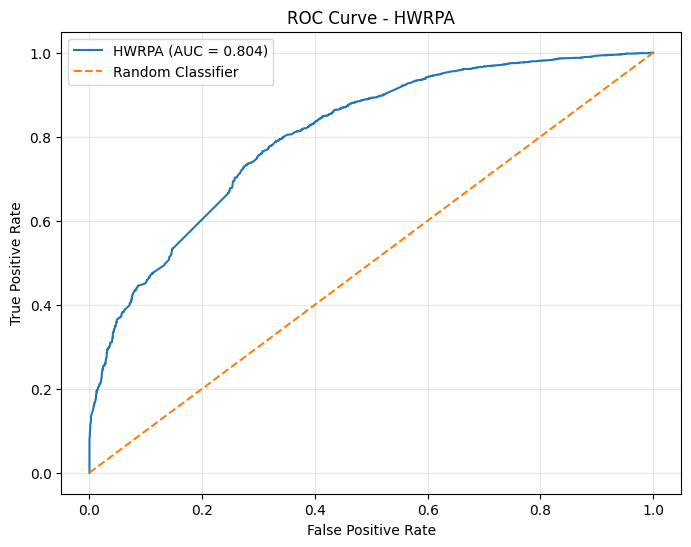

ROC-AUC: 0.8037


In [49]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, hwrpa_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"HWRPA (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - HWRPA")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("HWRPA_ROC_Curve.png", dpi=300)
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

,Feature,Importance
8,PHYSHLTH,0.056768
5,DIABETE4,0.051775
9,MENTHLTH,0.042629
0,_AGEG5YR,0.031701
7,GENHLTH,0.031158
11,INCOME3,0.027436
1,SEXVAR,0.026434
10,EDUCA,0.025796
6,BPHIGH6,0.022838
3,EXERANY2,0.022712


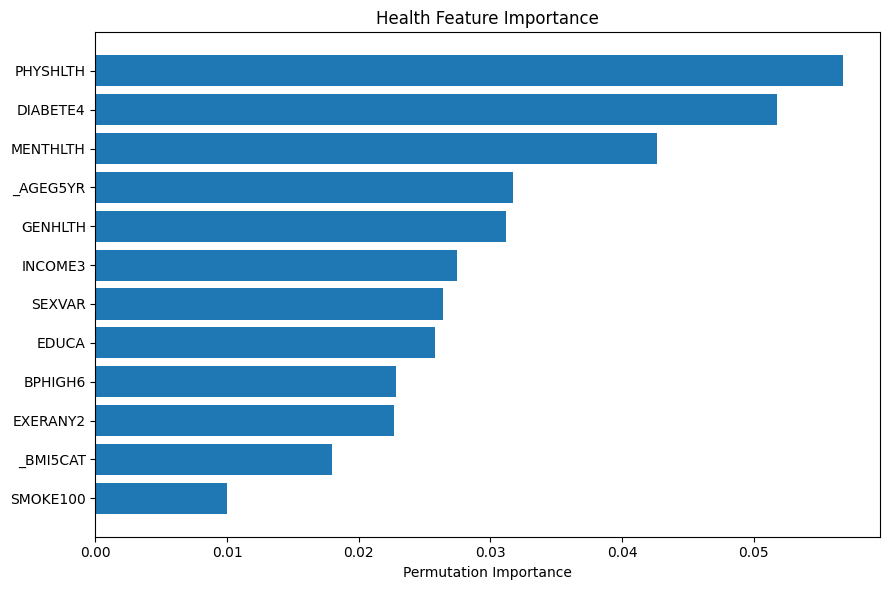

In [50]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

best_model_name = results_df.sort_values(
    "ROC-AUC", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

importance_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance_result.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Permutation Importance")
plt.title("Health Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("Feature_Importance.png", dpi=300)
plt.show()

In [51]:
# Select one test record
sample = X_test.iloc[[0]]

# Generate HWRPA probability
probability = hwrpa_predict(sample)[0]

print("INDIVIDUAL HEALTH ASSESSMENT")
print("=" * 40)

print("Estimated probability:", round(probability * 100, 2), "%")

if probability >= 0.5:
    print("Predicted class: Positive")
else:
    print("Predicted class: Negative")

print("\nInput health information:")
display(sample)

print("\nActual class:", int(y_test.iloc[0]))

INDIVIDUAL HEALTH ASSESSMENT
Estimated probability: 51.21 %
Predicted class: Positive

Input health information:


,_AGEG5YR,SEXVAR,_BMI5CAT,EXERANY2,SMOKE100,DIABETE4,BPHIGH6,GENHLTH,PHYSHLTH,MENTHLTH,EDUCA,INCOME3
426645,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN,2.0,NaN,4.0



Actual class: 0


In [53]:
import joblib

model_bundle = {
    "models": trained_models,
    "weights": hwrpa_weights,
    "features": list(X.columns),
    "threshold": 0.5
}

joblib.dump(
    model_bundle,
    "/content/HWRPA_Model.pkl"
)

print("Model saved successfully!")
print("File: HWRPA_Model.pkl")

Model saved successfully!
File: HWRPA_Model.pkl


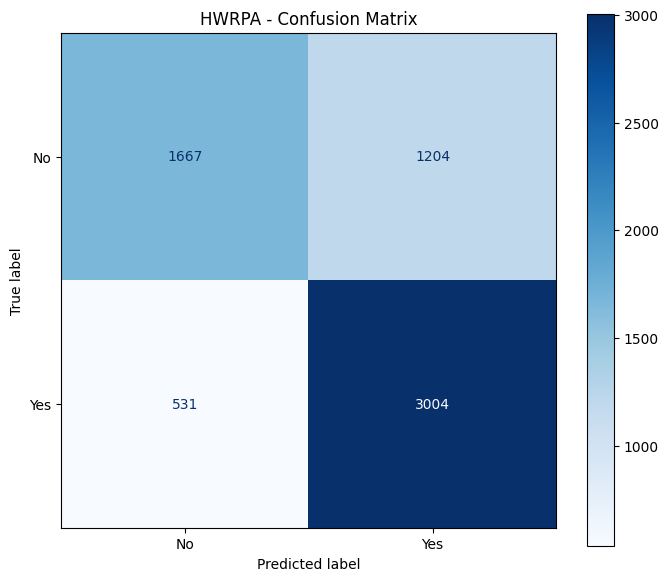

Confusion matrix saved successfully!


In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_test, final_predictions)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
).plot(ax=ax, cmap="Blues")

plt.title("HWRPA - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "/content/HWRPA_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [59]:
import os
from google.colab import files

result_files = [
    "HWRPA_Model.pkl",
    "HWRPA_ROC_Curve.png",
    "HWRPA_Confusion_Matrix.png",
    "Feature_Importance.png",
    "model_comparison.png"
]

for filename in result_files:
    path = "/content/" + filename

    if os.path.exists(path):
        print("Downloading:", filename)
        files.download(path)
    else:
        print("Not found:", filename)

Downloading: HWRPA_Model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: HWRPA_ROC_Curve.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

Downloading: Feature_Importance.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Not found: model_comparison.png


In [60]:
!pip -q install streamlit

In [61]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(
    page_title="AI Health Risk Prediction",
    page_icon="🩺",
    layout="wide"
)

# Load trained model
bundle = joblib.load("HWRPA_Model.pkl")

models = bundle["models"]
weights = bundle["weights"]
features = bundle["features"]

st.title("AI-Based Individual Health Risk Prediction Platform")

st.write(
    "An AI-based research prototype for individual health assessment "
    "using machine-learning techniques."
)

st.warning(
    "Academic demonstration only. This application does not provide "
    "medical diagnosis or clinically validated future-risk predictions."
)

st.header("Enter Individual Health Information")

# BRFSS-coded input options
options = {
    "_AGEG5YR": list(range(1, 14)),
    "SEXVAR": [1, 2],
    "_BMI5CAT": [1, 2, 3, 4],
    "EXERANY2": [1, 2],
    "SMOKE100": [1, 2],
    "DIABETE4": [1, 2, 3, 4],
    "BPHIGH6": [1, 2, 3, 4],
    "GENHLTH": [1, 2, 3, 4, 5],
    "EDUCA": [1, 2, 3, 4, 5, 6],
    "INCOME3": list(range(1, 12))
}

labels = {
    "_AGEG5YR": "Age group (BRFSS code)",
    "SEXVAR": "Sex (BRFSS code)",
    "_BMI5CAT": "BMI category (BRFSS code)",
    "EXERANY2": "Exercise response",
    "SMOKE100": "Lifetime smoking response",
    "DIABETE4": "Diabetes response code",
    "BPHIGH6": "High blood pressure response code",
    "GENHLTH": "General health (1=Excellent, 5=Poor)",
    "PHYSHLTH": "Physical unhealthy days (0–30)",
    "MENTHLTH": "Mental unhealthy days (0–30)",
    "EDUCA": "Education code",
    "INCOME3": "Income category code"
}

input_values = {}

with st.form("health_form"):

    for feature in features:

        label = labels.get(feature, feature)

        if feature in options:
            input_values[feature] = st.selectbox(
                label,
                options[feature]
            )

        elif feature in ["PHYSHLTH", "MENTHLTH"]:
            input_values[feature] = st.number_input(
                label,
                min_value=0,
                max_value=30,
                value=0
            )

        else:
            st.error(f"Input mapping not configured for {feature}.")
            st.stop()

    submitted = st.form_submit_button("Generate Assessment")

if submitted:

    input_df = pd.DataFrame(
        [input_values],
        columns=features
    )

    probability = 0.0

    for name, weight in weights.items():

        model_probability = models[name].predict_proba(
            input_df
        )[0, 1]

        probability += weight * model_probability

    st.header("Assessment Results")

    st.metric(
        "Model-estimated probability",
        f"{probability * 100:.2f}%"
    )

    st.info(
        "This probability estimates the selected BRFSS-reported "
        "health outcome. It is not a clinical risk score."
    )

    st.subheader("Contributing Input Information")
    st.dataframe(input_df, use_container_width=True)

    st.success("Assessment generated successfully.")

Writing /content/app.py


In [62]:
import os

print("Application created:", os.path.exists("/content/app.py"))
print("Trained model exists:", os.path.exists("/content/HWRPA_Model.pkl"))

Application created: True
Trained model exists: True


In [63]:
from google.colab import files

files.download("/content/app.py")
files.download("/content/HWRPA_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>